# Examine De ordine mundi

This notebook evaluates the hold-out work "X_ordine" against the test corpus to assess whether it was likely authored by **H** (Hildebert).

## Approach

We use stylometric analysis (Lambda-G) to compare 100 random ~1000-token samples from *De ordine* against known works by author H and M. A logistic regression model (trained in `evaluate_calibrate.ipynb`) converts raw scores into predicted probabilities.

## Stages

1. **Setup** — Load corpora and trained model
2. **Evaluation** — Run 100 parallel stylometric comparisons using Ray
3. **Visualization** — Histplot of raw scores + stripplot/violin of predicted probabilities

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import ray
from tqdm import tqdm
from typing import Any

from sentence_corpora import TwoLevelCorpus
from sentence_corpora.lambdag.av import LambdaGAV

import mpl_fontkit as fk

# Set up Roboto Condensed font
fk.install("Roboto Condensed")

# Set seaborn theme
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 300,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    },
)

Font name: `Roboto Condensed`


In [3]:
# Load corpora
test_corpus = TwoLevelCorpus.from_pickle("test_corpus.pkl")
ordine_corpus = TwoLevelCorpus.from_pickle("ordine_corpus.pkl")

print(
    f"ordine: {len(ordine_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in ordine_corpus)} tokens"
)
print(
    f"Test corpus: {len(test_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in test_corpus)} tokens"
)
print(f"Test corpus authors: {test_corpus.get_unique_values('author')}")

ordine: 281 sentences, 4084 tokens
Test corpus: 14080 sentences, 246659 tokens
Test corpus authors: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'M', 'NLC', 'OM', 'OSE', 'RC', 'RQ', 'RT', 'SG', 'U1', 'U10', 'U11', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9']


In [4]:
# Sampling function
def sample_corpus_to_token_count(corpus, target_tokens: int, rng: Any):
    """Sample sentences from corpus until we reach approximately target_tokens.

    Shuffles sentences and adds them until we exceed target_tokens.
    """
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)

    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break

    return type(corpus)(sampled, levels=corpus.levels)

In [5]:
# Initialize Ray
ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

2026-09-03 11:08:05,296	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


/opt/anaconda3/lib/python3.11/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


In [6]:
test_corpus.stats()

Author      Works    Sentences    Tokens    Mean Len
--------  -------  -----------  --------  ----------
AI              1          470     9,861        21
AeC             2          509    14,745        29
AeP             1          190     5,806        30.6
B               1          111     1,991        17.9
BC              1          830     6,994         8.4
DC              1          398     6,449        16.2
E               1          160     3,326        20.8
FB              1          775    10,684        13.8
GAp             1          423     6,004        14.2
GAr             1          532    11,367        21.4
GC              1          612    12,123        19.8
GM              1          184     3,379        18.4
GP              1          516    14,417        27.9
GVS             1          400     4,958        12.4
GiP             1          327     5,741        17.6
H               1          117     1,960        16.8
HA              1          372     5,049        13

### De ordine vs Hildebert

In [8]:
# Define the evaluation function for Ray
@ray.remote
def run_ordine_evaluation(
    seed: int,
    target_tokens: int = 1000,
) -> dict:
    """Run a single AV evaluation: De ordine vs author H."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Sample ~1000 tokens from De ordine as the unknown (q_corpus)
    q_corpus = sample_corpus_to_token_count(ordine_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity="H",
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=2000,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "score": result["score"],
        "corrected_score_sqrt": result["corrected_score_sqrt"],
        "corrected_score_hapax": result["corrected_score_hapax"],
        "n_unknown": result["unknown_sentences_used"],
        "unknown_tokens": result["unknown_tokens_used"],
    }

In [9]:
# Create 100 evaluation tasks
master_rng = np.random.default_rng(42)
TARGET_TOKENS = 1000
N_EVALUATIONS = 100

print(f"Creating {N_EVALUATIONS} evaluation tasks...")
tasks = []
for i in range(N_EVALUATIONS):
    seed = master_rng.integers(0, 2**32 - 1)
    tasks.append(run_ordine_evaluation.remote(seed, TARGET_TOKENS))
print(f"✓ Created {len(tasks)} tasks")

Creating 100 evaluation tasks...
✓ Created 100 tasks


In [10]:
# Execute all tasks in parallel with progress bar
print("\nExecuting tasks in parallel...")
results = []

for _ in tqdm(range(len(tasks)), desc="Evaluations"):
    ready, _ = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    results.append(result)
    tasks.remove(ready[0])

print(f"✓ Completed {len(results)} evaluations")
ray.shutdown()


Executing tasks in parallel...


Evaluations:   0%|                                     | 0/100 [00:00<?, ?it/s](pid=6890) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=6890)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=6890) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=6890)   from pandas.core import (
Evaluations: 100%|███████████████████████████| 100/100 [00:39<00:00,  2.54it/s]
(pid=6889) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see 

✓ Completed 100 evaluations


In [11]:
# Convert to DataFrame
df = pd.DataFrame(results)

print("=== Score Statistics ===")
print(df[["score", "corrected_score_sqrt", "corrected_score_hapax"]].describe())

print(f"\nUnknown token stats:")
print(f"  Mean: {df['unknown_tokens'].mean():.0f}")
print(f"  Min:  {df['unknown_tokens'].min()}")
print(f"  Max:  {df['unknown_tokens'].max()}")

=== Score Statistics ===
            score  corrected_score_sqrt  corrected_score_hapax
count  100.000000            100.000000             100.000000
mean    10.870859              0.342372               0.715323
std     43.788520              1.377643               3.081401
min    -97.097696             -3.055260              -7.114089
25%    -21.074452             -0.656854              -1.433492
50%     16.838417              0.530000               1.198170
75%     38.276357              1.202529               2.655951
max    142.046862              4.452027              10.046536

Unknown token stats:
  Mean: 1010
  Min:  1000
  Max:  1049


In [12]:
# Load the trained logistic regression model and compute probabilities
model = joblib.load("logistic_regression_model_uncorrected.pkl")
df["probability"] = model.predict_proba(df["score"].values.reshape(-1, 1))[:, 1]

print("=== Probability Statistics ===")
print(df["probability"].describe())
print(f"\nMean probability: {df['probability'].mean():.4f}")
print(f"Median probability: {df['probability'].median():.4f}")

=== Probability Statistics ===
count    100.000000
mean       0.260786
std        0.229864
min        0.004921
25%        0.068390
50%        0.219824
75%        0.376204
max        0.959919
Name: probability, dtype: float64

Mean probability: 0.2608
Median probability: 0.2198


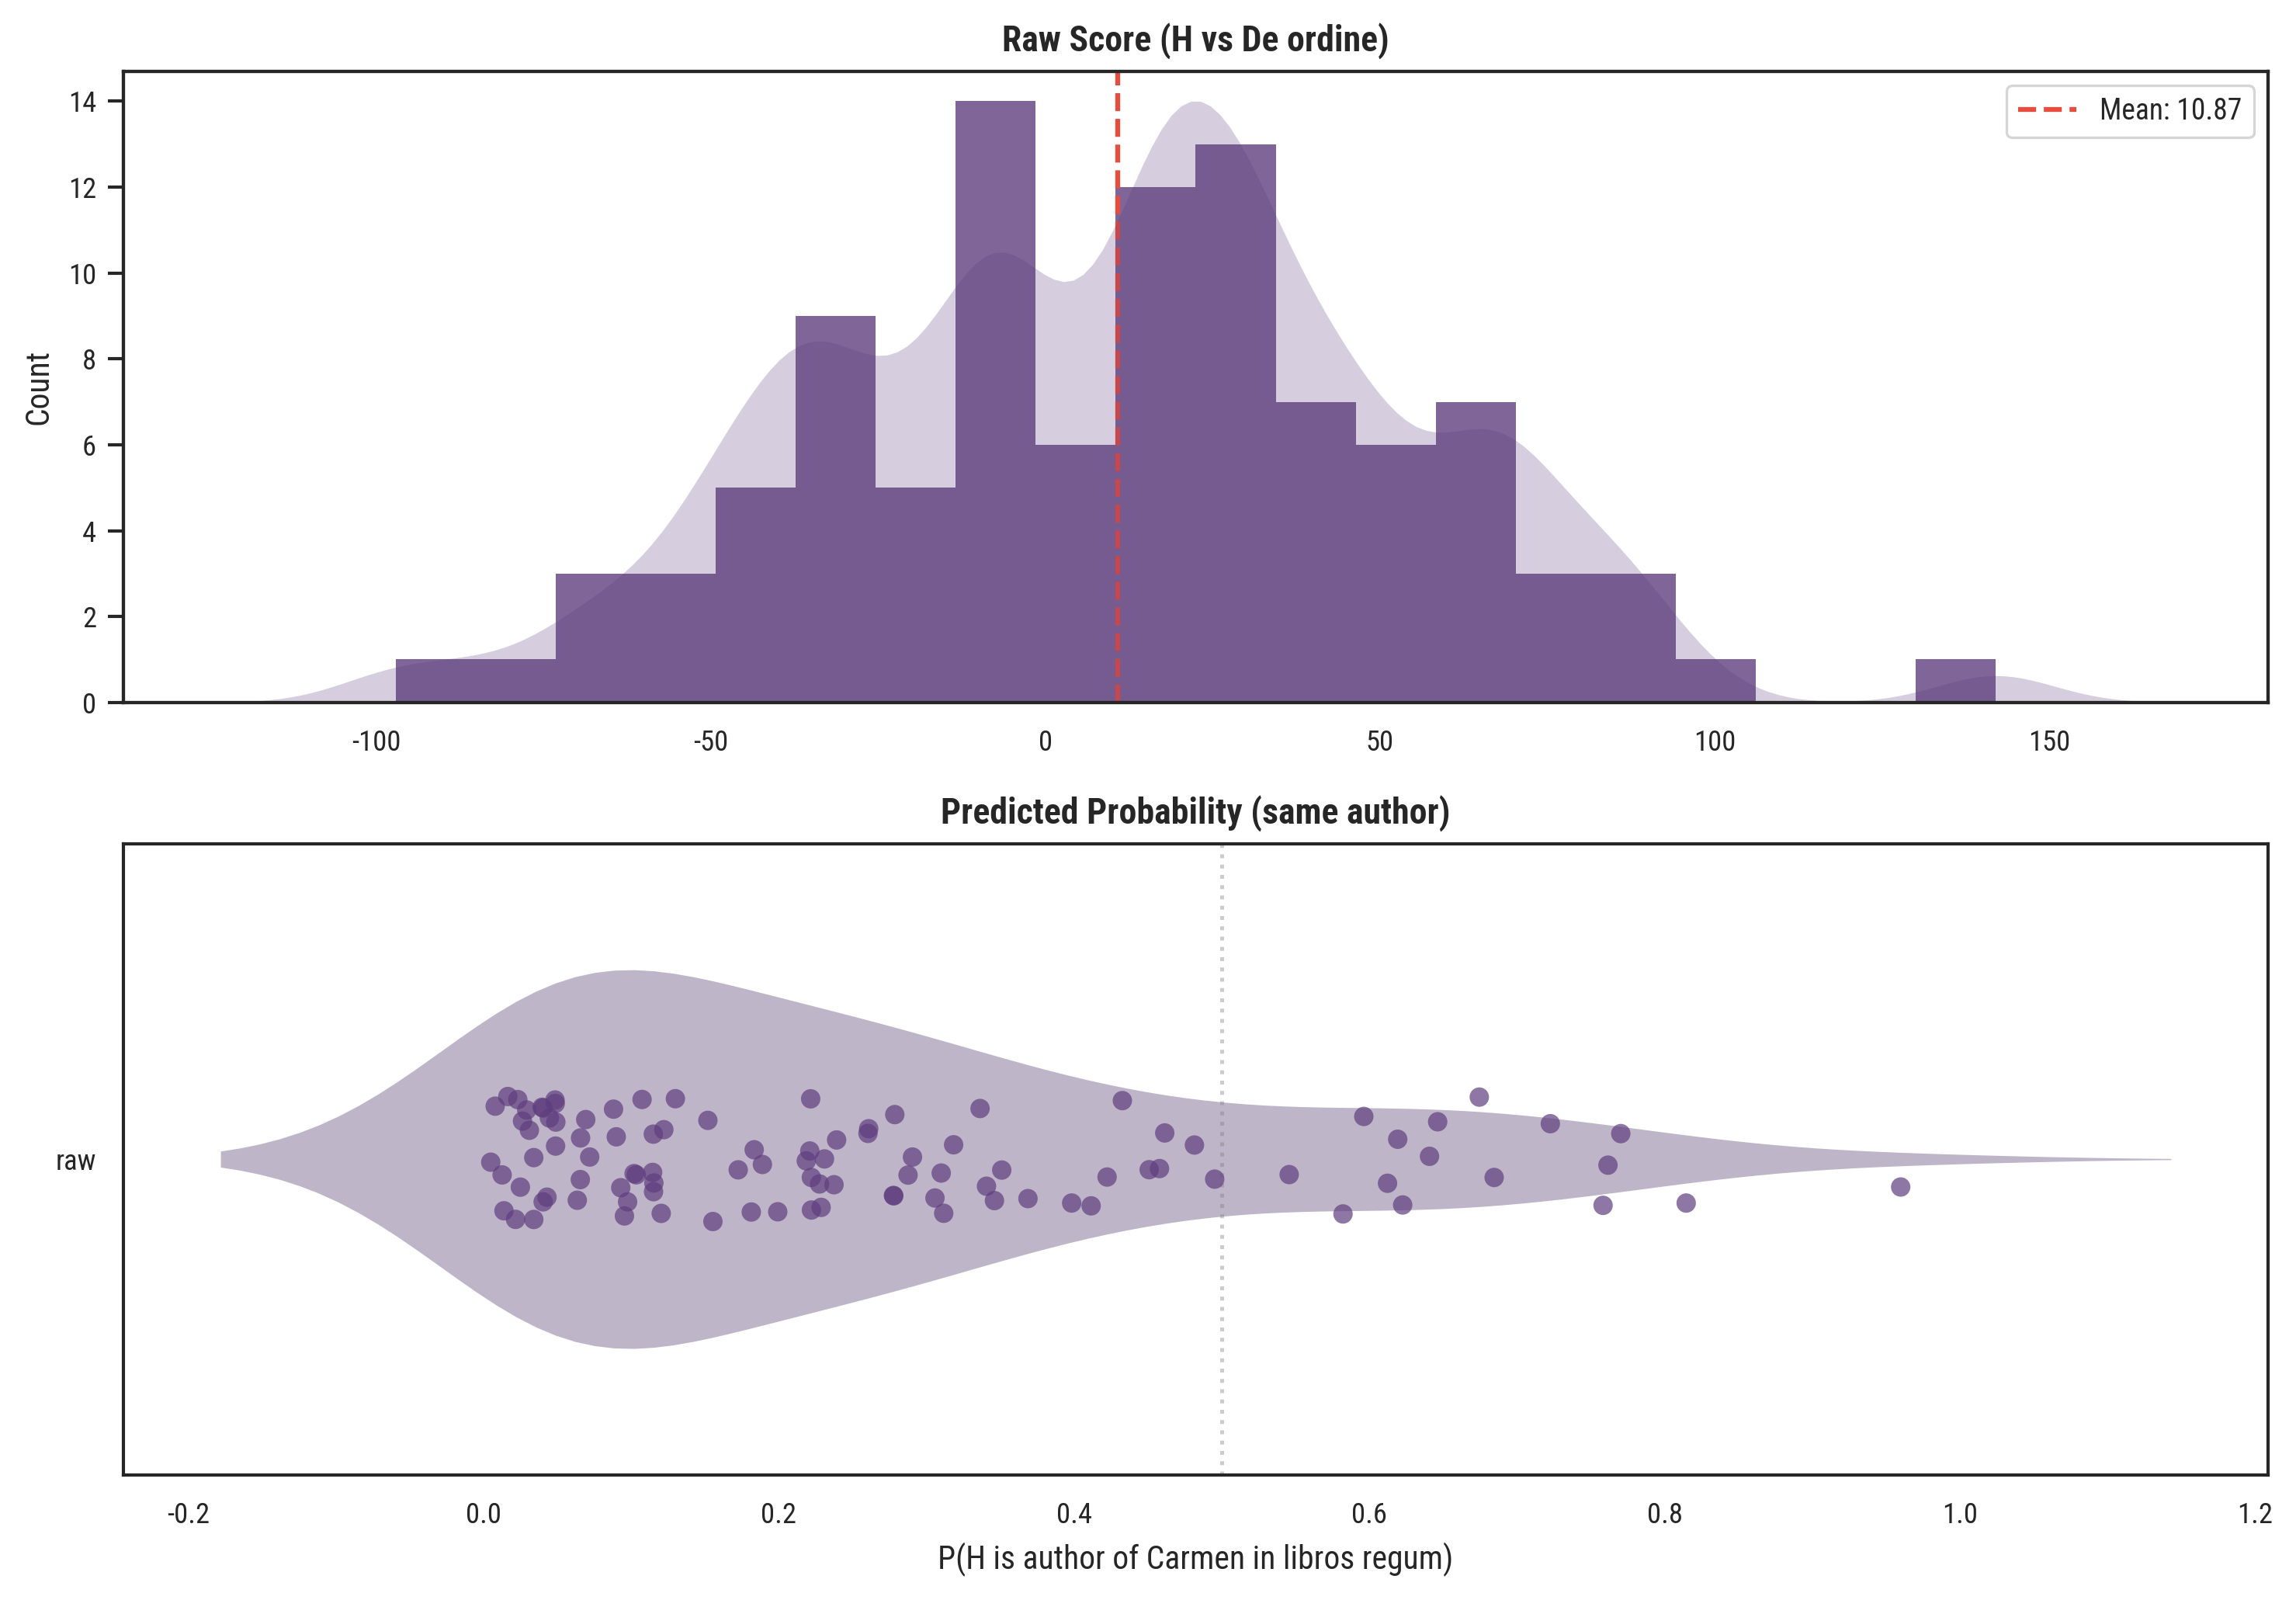

In [13]:
# Visualization: histplot of raw scores + stripplot/violin of probabilities
fig, axes = plt.subplots(2, 1, figsize=(10, 7), dpi=300)

for ax in axes:
    ax.grid(False)

color = "#5f3e7f"

# Row 1: Raw score distribution with KDE overlay
ax = axes[0]
sns.histplot(data=df, x="score", bins=20, ax=ax, color=color, alpha=0.8, linewidth=0)
ax2 = ax.twinx()
sns.kdeplot(
    data=df,
    x="score",
    ax=ax2,
    color=color,
    fill=True,
    linewidth=0,
    alpha=0.25,
    bw_adjust=0.5,
)
ax2.set_yticklabels([])
ax2.set_yticks([])
ax2.set_ylabel("")
ax.set_title("Raw Score (H vs De ordine)", fontweight="bold", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
mean_val = df["score"].mean()
ax.axvline(
    mean_val,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.2f}",
)
ax.legend(loc="upper right", fontsize=9)

# Row 2: Probability stripplot + violin
ax = axes[1]
ax.grid(False)
df_plot = pd.DataFrame(
    {
        "probability": df["probability"].tolist(),
        "model": ["raw"] * len(df),
    }
)
sns.violinplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    width=0.6,
    inner=None,
    density_norm="width",
    alpha=0.4,
    linewidth=0,
    legend=False,
)
sns.stripplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    size=6,
    jitter=True,
    alpha=0.7,
    legend=False,
)
ax.set_title("Predicted Probability (same author)", fontweight="bold", fontsize=11)
ax.set_xlabel("P(H is author of Carmen in libros regum)")
ax.set_ylabel("")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Evaluate Against All Authors

Now run the same 100 evaluations against every other author in the test corpus. For authors with fewer than 2000 tokens, we use their total token count as `known_size`.

In [15]:
# Compute known_size for each author
author_sizes = {}
for author in sorted(test_corpus.get_unique_values("author")):
    author_corpus = test_corpus.filter_by_level("author", author)
    tokens = sum(len(s.text.split()) for s in author_corpus)
    known_size = min(2000, tokens)
    author_sizes[author] = known_size
    print(f"  {author:6s}: {tokens:6d} tokens → known_size={known_size}")

  AI    :   9861 tokens → known_size=2000
  AeC   :  14745 tokens → known_size=2000
  AeP   :   5806 tokens → known_size=2000
  B     :   1991 tokens → known_size=1991
  BC    :   6994 tokens → known_size=2000
  DC    :   6449 tokens → known_size=2000
  E     :   3326 tokens → known_size=2000
  FB    :  10684 tokens → known_size=2000
  GAp   :   6004 tokens → known_size=2000
  GAr   :  11367 tokens → known_size=2000
  GC    :  12123 tokens → known_size=2000
  GM    :   3379 tokens → known_size=2000
  GP    :  14417 tokens → known_size=2000
  GVS   :   4958 tokens → known_size=2000
  GiP   :   5741 tokens → known_size=2000
  H     :   1960 tokens → known_size=1960
  HA    :   5049 tokens → known_size=2000
  HP    :   7640 tokens → known_size=2000
  IH    :   9513 tokens → known_size=2000
  II    :   8181 tokens → known_size=2000
  M     :   5515 tokens → known_size=2000
  NLC   :   5253 tokens → known_size=2000
  OM    :   8012 tokens → known_size=2000
  OSE   :   3955 tokens → known_si

In [16]:
# Define the per-author evaluation function
@ray.remote
def run_evaluation_for_author(
    seed: int,
    known_author: str,
    known_size: int,
    target_tokens: int = 1000,
) -> dict:
    """Run a single AV evaluation: De ordine vs a given known author."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    q_corpus = sample_corpus_to_token_count(ordine_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity=known_author,
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=known_size,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "author": known_author,
        "score": result["score"],
        "known_size": known_size,
    }

In [17]:
N_EVALUATIONS = 100
# Run evaluations for all authors
ray.init()
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

master_rng = np.random.default_rng(123)

all_tasks = []
task_info = []  # (author, seed) for each task

for author, known_size in author_sizes.items():
    for i in range(N_EVALUATIONS):
        seed = master_rng.integers(0, 2**32 - 1)
        all_tasks.append(
            run_evaluation_for_author.remote(seed, author, known_size, TARGET_TOKENS)
        )
        task_info.append(author)

print(f"Created {len(all_tasks)} tasks for {len(author_sizes)} authors")

# Execute all tasks
all_results = []
for _ in tqdm(range(len(all_tasks)), desc="All evaluations"):
    ready, _ = ray.wait(all_tasks, num_returns=1)
    result = ray.get(ready[0])
    all_results.append(result)
    all_tasks.remove(ready[0])

print(f"✓ Completed {len(all_results)} evaluations")
ray.shutdown()

2026-09-03 11:08:49,619	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


(pid=6952) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=6952)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=6952) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=6952)   from pandas.core import (


Created 3900 tasks for 39 authors


All evaluations: 100%|█████████████████████| 3900/3900 [22:56<00:00,  2.83it/s]
(pid=6957) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=6957)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x across cluster]
(pid=6957) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed). [repeated 7x across cluster]
(pid=6957)   from pandas.core import ( [repeated 7x across cluster]


✓ Completed 3900 evaluations


In [18]:
# Convert to DataFrame and compute probabilities
df_all = pd.DataFrame(all_results)
df_all["probability"] = model.predict_proba(df_all["score"].values.reshape(-1, 1))[:, 1]

# Summary: mean probability per author
summary = df_all.groupby("author")["probability"].agg(["mean", "std", "count"]).round(4)
summary = summary.sort_values("mean", ascending=False)
print("\n=== Mean Predicted Probability by Author ===")
print(summary)


=== Mean Predicted Probability by Author ===
          mean     std  count
author                       
U1      0.8662  0.1479    100
U3      0.8007  0.2217    100
FB      0.7243  0.2351    100
HA      0.6547  0.2848    100
U7      0.5310  0.2794    100
B       0.4295  0.2467    100
U11     0.3397  0.2677    100
M       0.3207  0.2637    100
DC      0.2473  0.2237    100
RT      0.2140  0.1686    100
H       0.2032  0.1942    100
GiP     0.1891  0.2097    100
GAp     0.1323  0.1560    100
HP      0.1175  0.1450    100
NLC     0.1149  0.1606    100
RC      0.1139  0.1358    100
U2      0.1118  0.1168    100
SG      0.1008  0.1241    100
AeC     0.1004  0.1452    100
RQ      0.0949  0.1246    100
GM      0.0615  0.0888    100
U5      0.0444  0.0627    100
GAr     0.0340  0.0707    100
GVS     0.0258  0.0431    100
GC      0.0148  0.0250    100
OM      0.0111  0.0235    100
OSE     0.0072  0.0110    100
U6      0.0067  0.0140    100
AI      0.0063  0.0158    100
U8      0.0061  0.0122  

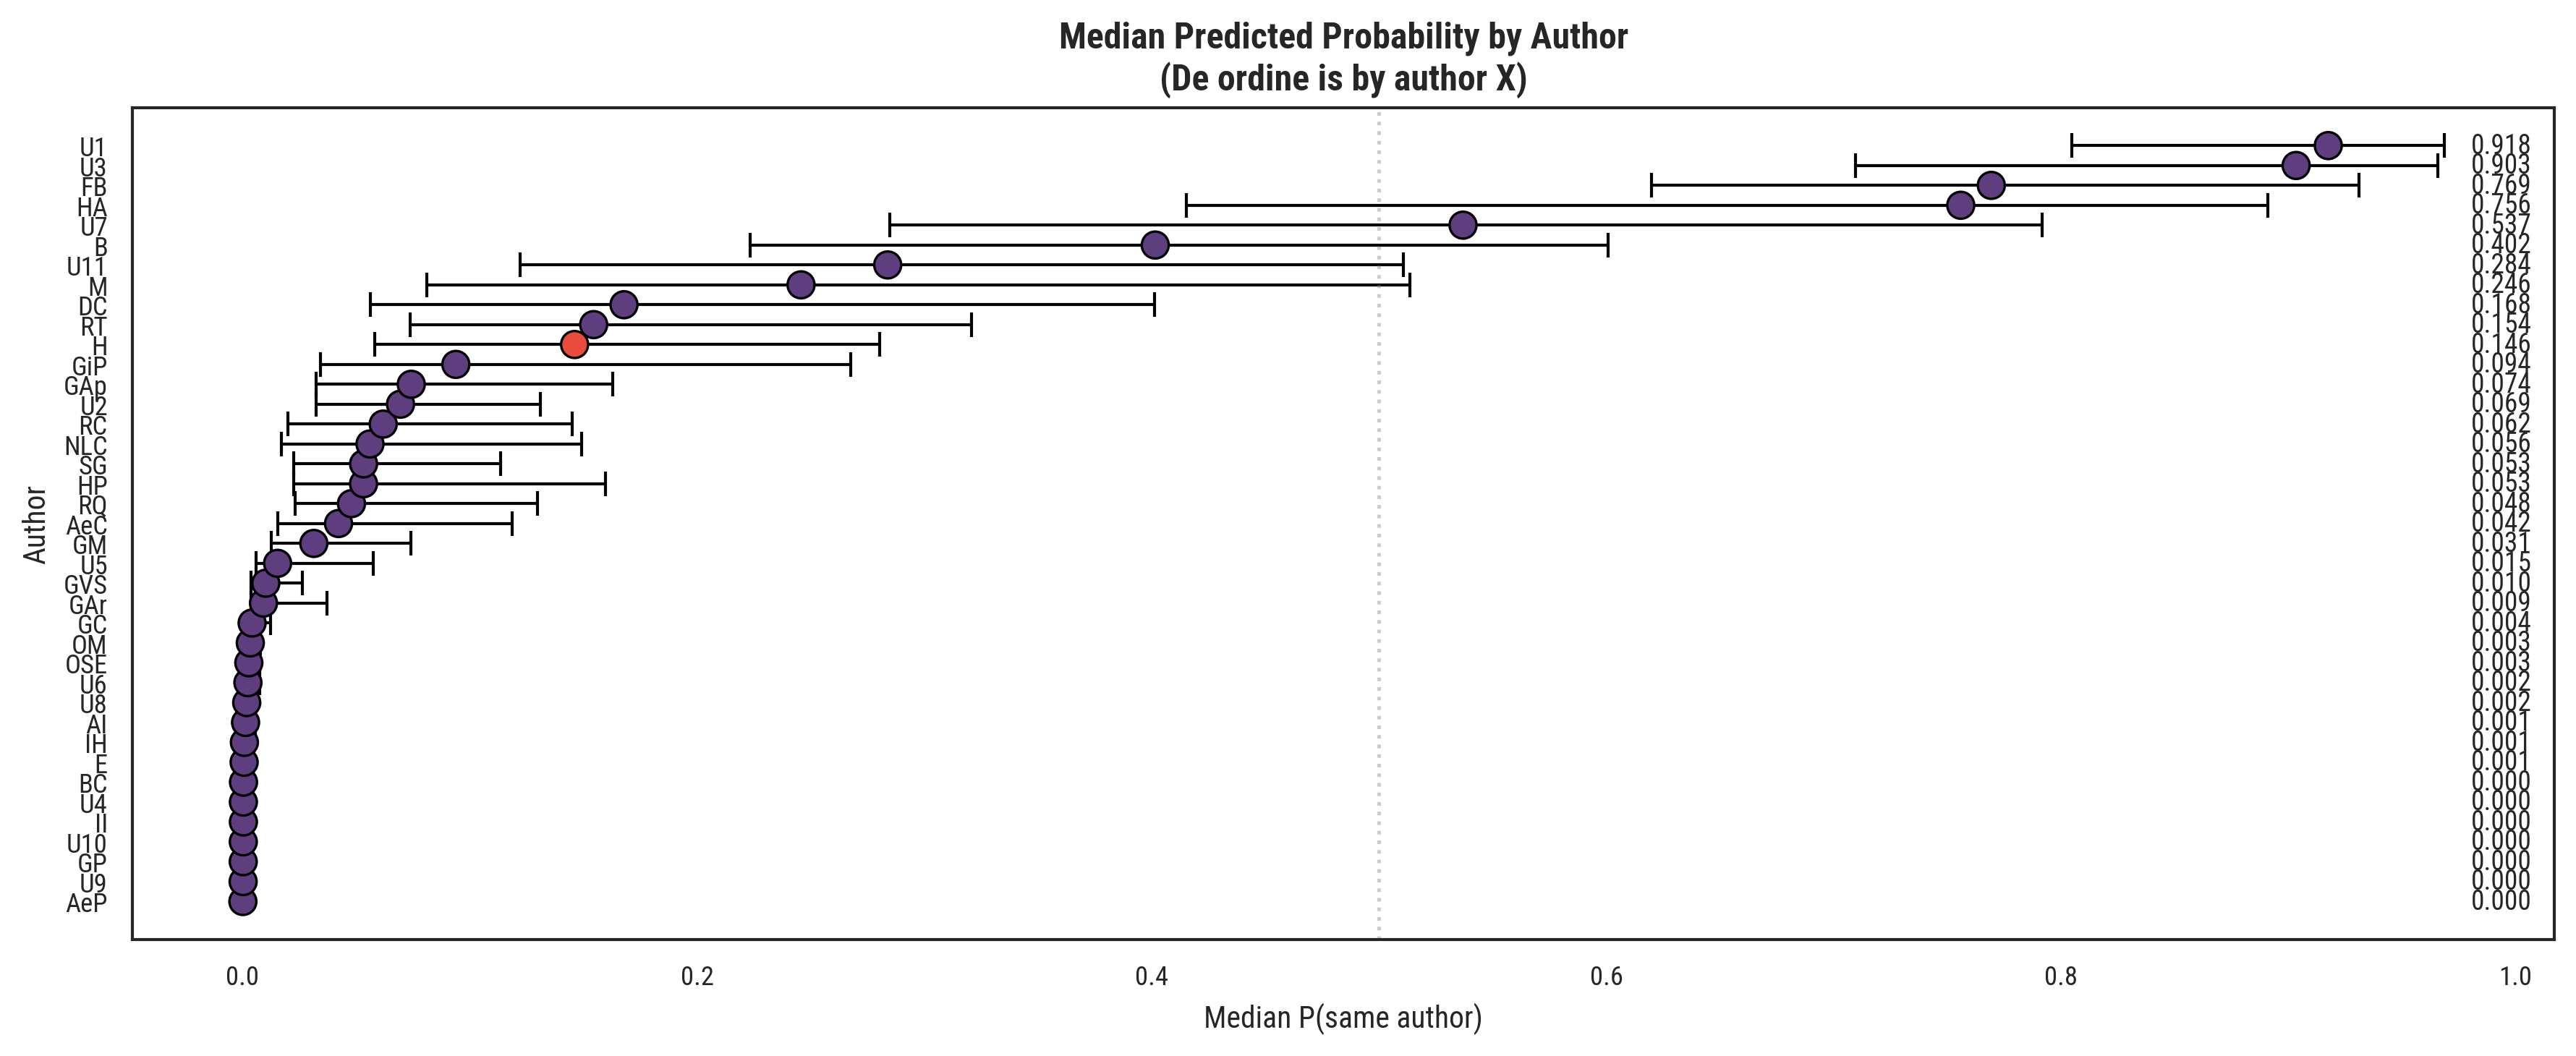

In [19]:
# Visualization: median probability per author with IQR whiskers
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
ax.grid(False)

# Compute stats per author
stats = df_all.groupby("author")["probability"].agg(
    ["median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]
)
stats.columns = ["median", "q25", "q75"]
stats = stats.sort_values("median", ascending=True)
authors_ordered = stats.index.tolist()

# Color: highlight H differently
colors = ["#e74c3c" if a == "H" else "#5f3e7f" for a in authors_ordered]

# IQR whiskers
for i, author in enumerate(authors_ordered):
    row = stats.loc[author]
    ax.plot(
        [row["q25"], row["q75"]],
        [i, i],
        color="black",
        linewidth=1,
        solid_capstyle="round",
    )
    for q in [row["q25"], row["q75"]]:
        ax.plot(q, i, "|", color="black", markersize=8, markeredgewidth=1)

# Median dots
ax.scatter(
    stats["median"].values,
    range(len(authors_ordered)),
    c=colors,
    s=80,
    zorder=5,
    edgecolors="black",
    linewidth=0.8,
)

ax.set_yticks(range(len(authors_ordered)))
ax.set_yticklabels(authors_ordered)
ax.set_title(
    "Median Predicted Probability by Author\n(De ordine is by author X)",
    fontweight="bold",
    fontsize=12,
)
ax.set_xlabel("Median P(same author)")
ax.set_ylabel("Author")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

# Add value labels on the right side of the plot
xlim = ax.get_xlim()
for i, (val, author) in enumerate(zip(stats["median"].values, authors_ordered)):
    ax.text(xlim[1] - 0.01, i, f"{val:.3f}", va="center", ha="right", fontsize=9)

plt.tight_layout()
plt.show()